In [1]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
import importlib
import RE as RE
importlib.reload(RE)
from RE import *
from unit_conversion import *
from scipy.optimize import fsolve

In [3]:
print(hasattr(RE, 'get_nuD_nuS'))

True


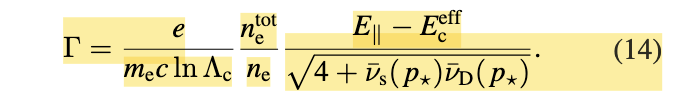

### Calculate $E_c^{eff}$
I did not run this and used the one defined in RE.py

In [4]:
### Functions for Ec_eff ####

def calcDelta(Eceff,nuD0,nuS1,tauRadInv,phib1,phib2,pc0):
    return (nuD0/nuS1**2)*(nuD0*tauRadInv/Eceff+phib1+phib2*np.log(pc0))

def calcEceff(delta,nuS0,nuS1,nuD1,nuD0,pc0):
    return nuS0 + nuS1*( (1+nuD1/nuD0)*np.log(pc0) + np.sqrt(2*delta+1))

def getEc_eff(Z,Z0,nj,T,B):
    
    # Returns the effective critical electric field with Ne impurities
    #       Z   : atomic number of each ion species
    #       Z0  : net charge of plasma for each ion species
    #       nj  : density of each ion species [m^(-3)]
    #       Z, Z0 and nj must be arrays of length nSpecies
    #       T   : temperature [eV]  (for calculation of the Coulomb logarithm)
    #       B   : magnetic field [T]
   
    # Constants for Ne
    ln_aBar_Ne = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
    ln_I_Ne = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    ntot = np.sum(Z * nj) # Bound + Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Zfulleff = np.sum(Z**2 * nj)/ne_free 
    lnLStar = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # Coul. Log
    Ne = Z - Z0 # No. of bound electrons

    ## calculate the constants nuD0, nuD1, nuS0, nuS1
    nuD0 = (1 + Zeff) - 2/3 * np.sum(Ne**2 * nj)/ne_free /lnLStar
    nuD1 = Zfulleff/lnLStar
    nuS0 = 1
    nuS1 = (1 + 3 * np.sum(Ne * nj)/ne_free)/(2*lnLStar)
    for i in range(1,Z.shape[0]):
        nuD0 = nuD0 + (Z[i]**2 - Z0[i]**2) * ln_aBar_Ne[Z0[i]] * (nj[i]/ne_free) / lnLStar
        nuS0 = nuS0 + Ne[i] * (-ln_I_Ne[Z0[i]]-1) * (nj[i]/ne_free) / lnLStar

    #### Radiation ####

    # synchrotron radiation term
    tauRadInv =  B**2/(ne_free/1e20)/(15.44*lnLStar);

    # bremsstrahlung term
    ALPHA = 1/137.036;
    bremsprefactor = ALPHA * Zfulleff/lnLStar;
    phib1 = bremsprefactor*0.35;
    phib2 = bremsprefactor*0.20;

    pc0 = nuD0/(2*nuS1);

    Ectot = ntot/ne_free # in units of E_c
    Eceff0 = Ectot
    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)
    delta1 = calcDelta(calcEceff(delta0,
                                nuS0,nuS1,nuD1,nuD0,pc0),
                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)

    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot
    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2);
    
    return Ectot * EceffOverEctot, Ectot


# Deflection and Slowing Down Frequencies

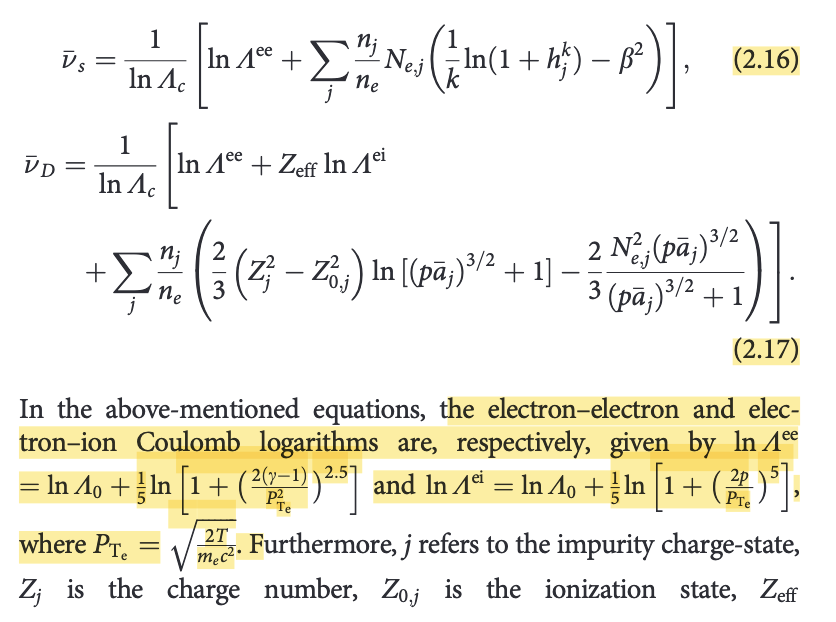

### Also didn't run this and used one defined in RE.py

In [5]:
# functions for collision frequencies and critical momentum pstar

def get_nuD_nuS(p,Z,Z0,nj,T):
    
    # p = normalized momentum
    # Z = max. ionization
    # Z0 = ionization level
    # nj = density [per cubic m]
    # T = temperature [eV]
    
    # Constants
    ln_aBar_Ne = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
    ln_I_Ne = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    
    
    aBar_Ne = np.exp(ln_aBar_Ne)
    I_Ne = np.exp(ln_I_Ne)
    k = 5
    
    # Other Quantities
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Ne = Z - Z0 # No. of bound electrons

    # Everything is a function of momentum p
    gamma = np.sqrt(1+p**2)
    beta = p**2 / (1 + p**2)
    
    # Coulomb Logs (also functions of p)
    PT = np.sqrt(2 * T / const.m_e / const.c**2) # Thermal velocity
    lnAc = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # RE-Thermal Coul. log
    lnA0 = 14.9 - 0.5 * np.log(ne_free/1e20) + np.log(T/1e3) # Thermal-Thermal Coul. Log
    lnAee = lnA0 + 1/5 * np.log(1 + (2*(gamma-1)/PT**2)**2.5)
    lnAei = lnA0 + 1/5 * np.log(1 + (2*p/PT)**5)
    # lnAee = lnAc + np.log(np.sqrt(gamma-1))
    # lnAei = lnAc + np.log(np.sqrt(2) * p)
    
    # Caluclate nuS and nuD (Bandaru + 2024)

    nuS = lnAee
    nuD = lnAee + Zeff * lnAei
    for j in range(1,Z.shape[0]):
        hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
        F1j = 1/k * np.log(1+hj**k) - beta**2
        pabar1p5 = (p*aBar_Ne[Z0[j]])**1.5
        nuS = nuS + (nj[j] / ne_free)  * Ne[j] * F1j
        nuD = nuD + (nj[j] / ne_free) * ( 
                      (2/3 * (Z[j]**2 - Z0[j]**2)) * np.log(pabar1p5+1)
                    - (2/3 * Ne[j]**2 * pabar1p5 / (pabar1p5+1))
                    )
#     # Hesslow + 2018    
#     nuS = lnAee
#     nuD = lnAee + Zeff * lnAei
#     for j in range(1,Z.shape[0]):
#         hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
#         nuS = nuS + (nj[j] / ne_free)  * Ne[j] * (np.log(hj) - beta**2)
#         nuD = nuD + (nj[j] / ne_free) * ( 
#                       (Z[j]**2 - Z0[j]**2) * np.log(p*aBar_Ne[Z0[j]])
#                     - 2/3 * Ne[j]**2
#                     )
        
    nuS = nuS / lnAc
    nuD = nuD / lnAc
    
    return nuD, nuS





In [6]:
def fn(pstar,E_star,Z,Z0,nj,T):
    # T [eV]
    # Pstar = normalized momentum
    # Estar = Epar / E_CH (E_CH = Connor Hastie Critical Field)
    nuD, nuS = get_nuD_nuS(pstar,Z,Z0,nj,T)
    return pstar * (E_star)**(0.5) - (nuS * nuD)**(1/4)

# Avalanching Rate

In [ ]:
def getHesslowAvalanchingRate(E_star,Z,Z0,nj,T,element,B=0): # Presently implemnted for Ne, must be implemented for Ar
    # Returns the avalanching rate in per second
    # E_star [-] = Parallel E-field / E_CH (E_CH = Connor Hastie Electric field)
    # Z = max. ionization; first element of array is deuterium, next is Neon
    # Z0 = ionization level; first element of array is 1, next is Neon ionization
    # nj = density of each species [per cubic m]
    # T = temperature [eV]

    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    ntot = np.sum(Z * nj) # Bound + Free electron density, per cubic m 
    lnAc = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # RE-Thermal Coul. log
    Eceff = RE.getEc_eff(Z,Z0,nj,T,B,element)[0] # Effective E-field, V/m
    pstar = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T))[0] # critical momentum [-]
    nuD, nuS =  RE.get_nuD_nuS(pstar,Z,Z0,nj,T,element) # Slowing down and deflection freq [-]
    
    ECH = RE.getConnorHastieField(ne_free, lnAc) # Connor Hastie Field [V/m]
    Epar = ECH * E_star # Parallel Electric Field V/m
    
    gamma = const.e / (const.m_e * const.c *lnAc) * (ntot / ne_free) * (Epar - Eceff) / np.sqrt(4 + nuS * nuD) # per second
    
    return gamma


Eceff [V/m] = 0.88


<>:27: SyntaxWarning: invalid escape sequence '\G'
<>:27: SyntaxWarning: invalid escape sequence '\G'
C:\Users\grace\AppData\Local\Temp\ipykernel_15460\3140925700.py:27: SyntaxWarning: invalid escape sequence '\G'
  plt.ylabel('$\Gamma \, [ms^{-1}]$')


(0.0, 100.0)

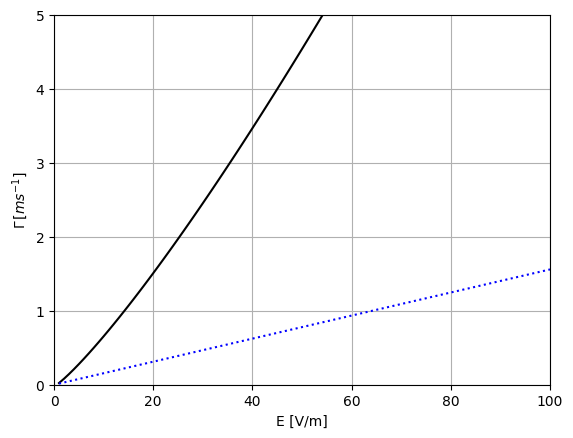

In [8]:
# Inputs

Epar = np.linspace(1,100,100) # V/m
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10
B = 0
ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
lnA = RE.getCoulombLog(ne_free,T) # Coul. Log
Ec = RE.getConnorHastieField(ne_free,lnA) # V/m 
Eceff = RE.getEc_eff(Z,Z0,nj,T,B)[0] # Effective E-field, V/m
E_star = Epar / Ec

### Print ####
print('Eceff [V/m] = %1.2f'%Eceff)

### Calculate Avalanching Rate ####
gamma = np.zeros_like(E_star)
for ii in range(Epar.shape[0]):
    out = getHesslowAvalanchingRate(E_star[ii],Z,Z0,nj,T,'Ne',B) # per s
    gamma[ii] = out


plt.plot(Epar,gamma*1e-3,'k-')
plt.xlabel('E [V/m]')
plt.ylabel('$\Gamma \, [ms^{-1}]$')
plt.grid()

# RP Model
nD = nj[0] # per cubic m
ne  = nD 
T = 10 # eV
lnA = RE.getCoulombLog(ne,T)
Ec = RE.getConnorHastieField(ne,lnA) # V/m 
Z = 1
inv_aspect_ratio = 2/6.2

gamma_RP2 = RE.get_avalance_growth_rate_RP2(Epar/Ec,ne,inv_aspect_ratio,lnA,Z) # per s

plt.plot(Epar,gamma_RP2*1e-3,'b:')

plt.ylim([0,5])
plt.xlim([0,100])



Reproduce the following figure from Hesslow et al. 2019 (NOTE: this caluclation is for Argon) 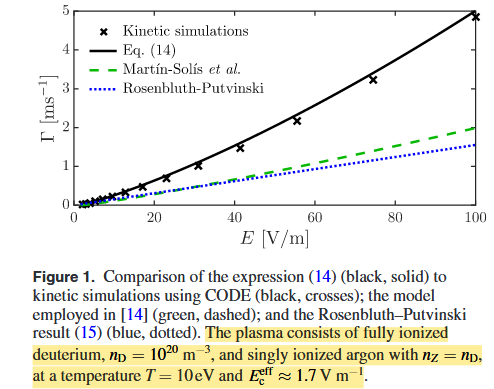

Eceff [V/m] = 1.71


<>:28: SyntaxWarning: invalid escape sequence '\G'
<>:28: SyntaxWarning: invalid escape sequence '\G'
C:\Users\grace\AppData\Local\Temp\ipykernel_15460\2872845709.py:28: SyntaxWarning: invalid escape sequence '\G'
  plt.ylabel('$\Gamma \, [ms^{-1}]$')


(0.0, 100.0)

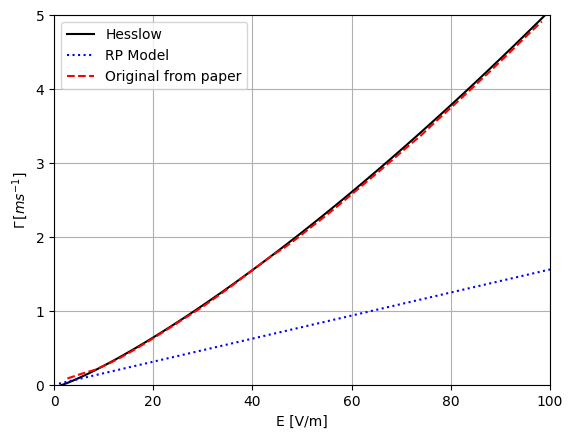

In [ ]:
import pandas as pd

Epar = np.linspace(1,100,100) # V/m
Z = np.array([1,18]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10
B = 0
ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
#lnA = RE.getCoulombLog(ne_free,T) # Coul. Log
lnA = 14.6 + 0.5 * np.log(T / (1e20/1e20))
Ec = RE.getConnorHastieField(ne_free,lnA) # V/m 
Eceff = RE.getEc_eff(Z,Z0,nj,T,B, 'Ar')[0] # Effective E-field, V/m
E_star = Epar / Ec

# Print 
print('Eceff [V/m] = %1.2f'%Eceff)

### Calculate Avalanching Rate ####
gamma = np.zeros_like(E_star)
for ii in range(Epar.shape[0]):
    out = getHesslowAvalanchingRate(E_star[ii],Z,Z0,nj,T,'Ar',B) # per s
    gamma[ii] = out


plt.plot(Epar,gamma*1e-3,'k-')
plt.xlabel('E [V/m]')
plt.ylabel('$\Gamma \, [ms^{-1}]$')
plt.grid()

# RP Model
nD = nj[0] # per cubic m
ne  = nD 
T = 10 # eV
lnA = RE.getCoulombLog(ne,T)
Ec = RE.getConnorHastieField(ne,lnA) # V/m 
Z = 1
inv_aspect_ratio = 2/6.2

gamma_RP2 = RE.get_avalance_growth_rate_RP2(Epar/Ec,ne,inv_aspect_ratio,lnA,Z) # per s

plt.plot(Epar,gamma_RP2*1e-3,'b:')

# Original Paper .csv extraction overlay

og_data = pd.read_csv('Hesslow2019Extraction.csv', header= None)
E_hes = og_data.iloc[:,0].values
gamma_hes = og_data.iloc[:,1].values

plt.plot(E_hes, gamma_hes, 'r--', label='Hes2019')


plt.legend(['Hesslow', 'RP Model', 'Original from paper'])

plt.ylim([0,5])
plt.xlim([0,100])

